# ML-enhanced vs rule-based trend following — results walkthrough

Everything below is read from the experiment registry (`results/tfml/registry.sqlite`) produced by `scripts/tfml_run.py`. See `paper/paper.md` for the write-up and `docs/TFML_FRAMEWORK.md` for the pipeline. Re-run `scripts/tfml_make_notebook.py` to refresh.

In [1]:
import pandas as pd, numpy as np, json
from qresearch.tfml import registry as R, strategies as S
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
runs = R.read('select run_id, started, n_instruments, n_rows, code_hash, dataset_hash from runs')
runs

,run_id,started,n_instruments,n_rows,code_hash,dataset_hash
0,null_randomwalk,Wed Oct 7 12:30:26 2026,60,480000,c5eca8e4b21125d6,synthetic-garch-t5
1,ablation_all,Wed Oct 7 14:54:03 2026,174,1100307,05ed4f98a50abe35,db291a67e4f96983
2,benchmark,Wed Oct 7 17:34:56 2026,174,1100307,05ed4f98a50abe35,db291a67e4f96983
3,robust_holdout2013,Wed Oct 7 18:15:36 2026,174,1100307,05ed4f98a50abe35,db291a67e4f96983
4,crypto_intraday_4h,Wed Oct 7 18:24:56 2026,12,216493,05ed4f98a50abe35,9f6733464b6d661c
5,crypto_intraday_1h,Wed Oct 7 18:31:22 2026,12,865205,05ed4f98a50abe35,9f6733464b6d661c
6,robust_single_stocks,Wed Oct 7 18:52:02 2026,49,407598,05ed4f98a50abe35,9b99beb8f0605415
7,robust_rolling10y,Wed Oct 7 19:09:47 2026,174,1100307,05ed4f98a50abe35,db291a67e4f96983
8,ablation_momentum,Thu Oct 8 13:56:32 2026,174,1100307,1024caac02f900cb,db291a67e4f96983
9,ablation_volatility,Thu Oct 8 14:04:57 2026,174,1100307,1024caac02f900cb,db291a67e4f96983


## 1. Lineage of one result (Strategy → … → Result)

In [2]:
R.read("""select strategy, indicators, market, instrument, dataset, ml_stage, ml_model, selected_models,
validation, backtest, sharpe, base_sharpe, d_sharpe, p_boot_two, result_path, code_hash, exp_id
from experiments where run_id='benchmark' and level='portfolio' and ml_model='selected' limit 5""")

,strategy,indicators,market,instrument,dataset,ml_stage,ml_model,selected_models,validation,backtest,sharpe,base_sharpe,d_sharpe,p_boot_two,result_path,code_hash,exp_id
0,sma_50_200,"[""SMA""]",ALL,PORTFOLIO,"{""frequency"": ""daily"", ""n_instruments"": 174, ""...",S1_filter,selected,"{""et"": 16, ""logreg"": 3, ""rf"": 2}",wf_expanding_val2y_step1y,next_open|cost1|vol_target0.1,0.672365,0.419553,0.252812,0.0560,results\tfml\benchmark\sma_50_200.parquet,c5eca8e4b21125d6,7688821b6c10b684
1,sma_50_200,"[""SMA""]",ALL,PORTFOLIO,"{""frequency"": ""daily"", ""n_instruments"": 174, ""...",S2_regime,selected,"{""lgbm"": 4, ""rf"": 4, ""logreg"": 8, ""et"": 3, ""ml...",wf_expanding_val2y_step1y,next_open|cost1|vol_target0.1,0.369429,0.419553,-0.050124,0.5650,results\tfml\benchmark\sma_50_200.parquet,c5eca8e4b21125d6,7afbbdbba8bc95de
2,sma_50_200,"[""SMA""]",ALL,PORTFOLIO,"{""frequency"": ""daily"", ""n_instruments"": 174, ""...",S3_sizing,selected,"{""logreg"": 5, ""lgbm"": 2, ""et"": 7, ""rf"": 4, ""ml...",wf_expanding_val2y_step1y,next_open|cost1|vol_target0.1,0.644974,0.419553,0.225421,0.0685,results\tfml\benchmark\sma_50_200.parquet,c5eca8e4b21125d6,110ee38825cef46c
3,sma_50_200,"[""SMA""]",ALL,PORTFOLIO,"{""frequency"": ""daily"", ""n_instruments"": 174, ""...",S4_exit,selected,"{""mlp"": 7, ""et"": 6, ""lgbm"": 4, ""logreg"": 1, ""r...",wf_expanding_val2y_step1y,next_open|cost1|vol_target0.1,0.708397,0.419553,0.288844,0.1060,results\tfml\benchmark\sma_50_200.parquet,c5eca8e4b21125d6,c24ff5d6c2565aea
4,sma_50_200,"[""SMA""]",ALL,PORTFOLIO,"{""frequency"": ""daily"", ""n_instruments"": 174, ""...",S5_params,selected,"{""lgbm"": 7, ""rf"": 2, ""logreg"": 6, ""et"": 3, ""ml...",wf_expanding_val2y_step1y,next_open|cost1|vol_target0.1,0.521035,0.419553,0.101482,0.3230,results\tfml\benchmark\sma_50_200.parquet,c5eca8e4b21125d6,0f6623630d42db44


## 2. Rule-based baselines (benchmark, OOS portfolio level)

In [3]:
b = R.read("select strategy, strategy_family, cagr, sharpe, sortino, calmar, max_drawdown, turnover, cost_drag, "
           "win_rate_trades, profit_factor_trades from experiments where run_id='benchmark' and level='portfolio' and ml_stage='none'")
b.sort_values('sharpe', ascending=False).round(3)

,strategy,strategy_family,cagr,sharpe,sortino,calmar,max_drawdown,turnover,cost_drag,win_rate_trades,profit_factor_trades
6,faber_10m,price_vs_ma,0.023,0.849,1.155,0.335,-0.070,3.757,0.001,0.367,4.668
24,abs_mom_12m,time_series_momentum,0.023,0.841,1.139,0.367,-0.062,3.060,0.001,0.445,5.311
23,tsmom_252,time_series_momentum,0.015,0.488,0.672,0.157,-0.096,14.086,0.004,0.355,1.796
8,bll_vma_200,price_vs_ma,0.014,0.455,0.633,0.175,-0.081,7.704,0.002,0.218,1.606
0,sma_50_200,ma_crossover,0.013,0.420,0.572,0.100,-0.131,5.762,0.002,0.334,1.797
25,tsmom_multi,time_series_momentum,0.008,0.348,0.487,0.151,-0.055,26.336,0.007,0.335,1.295
26,linreg_63,time_series_momentum,0.007,0.251,0.347,0.088,-0.084,9.815,0.003,0.338,1.218
7,gmma,ma_crossover,0.006,0.229,0.322,0.067,-0.094,18.777,0.005,0.287,1.205
16,turtle_55_20,breakout,0.005,0.214,0.299,0.069,-0.078,7.667,0.002,0.357,1.263
35,ichimoku,directional,0.005,0.194,0.273,0.046,-0.109,21.643,0.006,0.297,1.133


## 3. ML improvement by stage (selected model, bootstrap p-values, BH across 39×5 tests)

In [4]:
from qresearch.tfml import stats as ST
pf = R.read("select strategy, ml_stage, base_sharpe, sharpe, d_sharpe, p_boot_two from experiments "
            "where run_id='benchmark' and level='portfolio' and ml_model='selected'")
pf['p_bh'] = ST.bh(pf.p_boot_two.values)
pf.groupby('ml_stage').agg(mean_dSharpe=('d_sharpe','mean'), share_improved=('d_sharpe', lambda x: (x>0).mean()),
    sig_pos_bh=('p_bh', lambda p: int((p<0.05).sum()))).round(3)

,mean_dSharpe,share_improved,sig_pos_bh
ml_stage,,,
S1_filter,0.470,0.974,31
S2_regime,-0.007,0.462,1
S3_sizing,0.444,0.974,33
S4_exit,0.282,0.949,16
S5_params,0.164,0.846,4


In [5]:
pf.pivot(index='strategy', columns='ml_stage', values='d_sharpe').round(2)

ml_stage,S1_filter,S2_regime,S3_sizing,S4_exit,S5_params
strategy,,,,,
abs_mom_12m,0.01,-0.20,-0.01,-0.29,-0.12
adx_dmi_14,0.56,0.10,0.48,0.42,0.07
aroon_25,0.46,-0.17,0.50,0.28,0.21
bll_vma_200,0.27,-0.01,0.31,0.17,0.01
bollinger_20_2,0.47,-0.02,0.48,0.32,0.23
cci_20_100,0.48,-0.10,0.49,0.35,0.14
chande_kroll,0.43,0.05,0.54,0.30,0.16
chandelier_22_3,0.34,0.09,0.60,0.24,-0.03
dema_20_50,0.54,-0.12,0.57,0.46,0.37


## 4. Model comparison and selection frequency

In [6]:
m = R.read("select ml_stage, ml_model, avg(d_sharpe) mean_dSharpe, count(*) n from experiments where run_id='benchmark' "
           "and level='portfolio' and ml_stage!='none' group by ml_stage, ml_model")
m.pivot(index='ml_model', columns='ml_stage', values='mean_dSharpe').round(3)

ml_stage,S1_filter,S2_regime,S3_sizing,S4_exit,S5_params
ml_model,,,,,
et,0.539,0.085,0.476,0.359,0.171
lgbm,0.437,0.035,0.413,0.302,0.194
logreg,0.434,0.070,0.362,0.256,0.170
mlp,0.348,-0.005,0.287,0.186,0.153
rf,0.507,0.030,0.462,0.338,0.184
selected,0.470,-0.007,0.444,0.282,0.164


In [7]:
sel = R.read("select stage, model, sum(selected) times_selected from ml_selection where run_id='benchmark' group by stage, model")
sel.pivot(index='model', columns='stage', values='times_selected')

stage,S1_filter,S2_regime,S3_sizing,S4_exit,S5_params
model,,,,,
et,414,189,332,248,164
lgbm,91,165,131,169,247
logreg,101,179,128,144,146
mlp,77,107,79,124,147
rf,136,179,149,134,115


## 5. Composite multi-strategy portfolio (OOS)

,config,cagr,total_return,ann_vol,sharpe,sortino,calmar,max_drawdown,pct_pos_years,stability_r2,d_sharpe,p_boot_two,ci_lo,ci_hi
0,base,0.000,0.001,0.022,0.014,0.019,0.001,-0.095,0.524,-0.082,NaN,NaN,NaN,NaN
1,S1_filter,0.010,0.223,0.016,0.604,0.821,0.238,-0.041,0.714,0.892,0.590,0.003,0.239,0.955
2,S2_regime,0.000,0.005,0.011,0.025,0.034,0.006,-0.038,0.524,-0.128,0.012,0.934,-0.267,0.295
3,S3_sizing,0.014,0.347,0.026,0.572,0.781,0.235,-0.062,0.810,0.874,0.559,0.001,0.257,0.870
4,S4_exit,0.005,0.112,0.013,0.391,0.537,0.111,-0.046,0.714,0.680,0.378,0.008,0.095,0.665
5,S5_params,0.005,0.103,0.021,0.237,0.329,0.088,-0.054,0.571,0.428,0.224,0.012,0.056,0.404


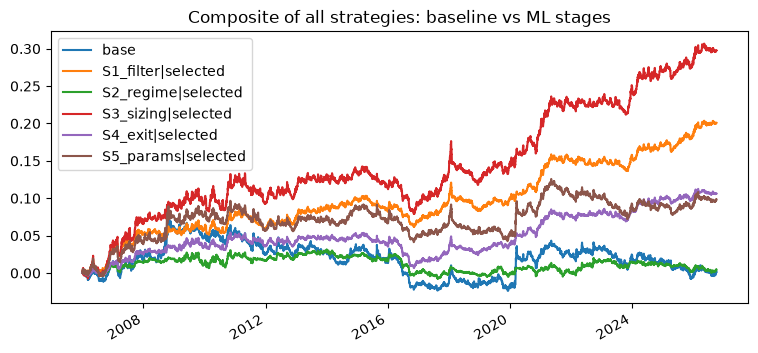

In [8]:
comp = pd.read_csv('../../paper/tables/benchmark_composite_daily_returns.csv', index_col=0, parse_dates=True)
ax = np.log((1+comp).cumprod()).plot(figsize=(9,4), title='Composite of all strategies: baseline vs ML stages')
pd.read_csv('../../paper/tables/benchmark_T17_composite_portfolio.csv').round(3)

## 6. Robustness across runs (validation method, frequency, survivorship-biased universe)

In [9]:
pd.read_csv('../../paper/tables/T18_cross_run_robustness.csv').round(3)

,run,stage,n_strategies,mean_base_sharpe,mean_dSharpe,median_dSharpe,share_improved,sig_pos_bh,sig_neg_bh
0,benchmark,S1_filter,39,0.007,0.470,0.498,0.974,31,0
1,benchmark,S2_regime,39,0.007,-0.007,-0.006,0.462,1,0
2,benchmark,S3_sizing,39,0.007,0.444,0.481,0.974,33,0
3,benchmark,S4_exit,39,0.007,0.282,0.296,0.949,15,1
4,benchmark,S5_params,39,0.007,0.164,0.165,0.846,4,0
5,robust_holdout2013,S1_filter,39,-0.080,0.620,0.674,0.974,32,0
6,robust_holdout2013,S2_regime,39,-0.080,0.124,0.115,0.769,0,2
7,robust_holdout2013,S3_sizing,39,-0.080,0.393,0.393,0.949,20,0
8,robust_holdout2013,S4_exit,39,-0.080,0.301,0.349,0.949,16,1
9,robust_holdout2013,S5_params,39,-0.080,0.185,0.224,0.846,2,0
